# Baseline Removal for the AWA EO / BPD Signal — Two Methods Compared

**Question.** Each balanced-photodiode (BPD) scope trace is an 81.25 MHz laser
pulse train (period $T = 12.31$ ns, ~9 peaks in the 100 ns window). Exactly one
pulse — the **5th peak, at ~52 ns** — is electro-optically modulated by the THz
field of the AWA bunch. To recover the EO signal we must subtract the
*unmodulated* laser carrier underneath that pulse. This notebook compares the two
baseline-removal strategies and cross-checks the peak-extraction logic against the
reference implementation `ANL_Experiment_Data_Extraction_LIAM/extremas.py`.

| | **Method A — Peak 5 $-$ Peak 4** (extrema extraction) | **Method B — Period fill** |
|---|---|---|
| Baseline model | the 4th peak (the pulse immediately before the modulated one) | the one clean laser period *before* the window, tiled across it |
| Readout | `max` of the 5th-peak window $-$ `max` of the 4th-peak window | signed mean of the residual over $\pm25$ samples at the max-variance probe time |
| Samples used | 2 window maxima | the whole $[45,100]$ ns window (~2750 samples) |
| Filtering | none | **none** — the FFT low-pass has been removed (see note) |
| Sign | positive-extremum only | bipolar (keeps sign) |
| Reference code | **`extremas.py`** (validated in §2b) | main characterization notebook |

**Changes from the previous version of this notebook**
1. **The FFT low-pass is removed from Method B (period fill).** Both methods now
   operate at full detector bandwidth, so the comparison isolates the *windowing
   and readout* differences — not the filter. Period fill still averages its
   $\pm25$-sample probe window (~50 samples), which is its only remaining noise
   benefit over the two-sample peak difference.
2. **Method A is cross-checked against `extremas.py`** (§2b): `extremas.py`
   boxcar-smooths (moving average, width 201) *only* to locate the half-cycle
   intervals via mean-crossings, then reads each extremum from the **raw** trace.
   That is exactly the peak-window `max` this notebook uses.

**The key relationship.** The 4th peak sits at ~39.7 ns, one full period *before*
the modulated 5th peak at ~52 ns, just outside the signal window $[45,100]$ ns.
Period fill builds the 5th-peak baseline by pulling the sample one period
earlier — i.e. **from the 4th peak**. So *Method A (peak 5 $-$ peak 4) is the
coarse, single-sample special case of Method B (period fill).* Everything below
quantifies what the extra machinery of period fill buys over the two-peak
subtraction.

## 0 · Setup — constants, data, and both reductions

In [2]:
import os
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import find_peaks
from scipy.stats import linregress

# Run from repo root so Data_raw/ resolves whether launched from Analysis/ or root
if os.path.basename(os.getcwd()) == 'Analysis':
    os.chdir('..')
os.makedirs('Results/method_comparison', exist_ok=True)

# ── instrument / analysis constants (mirror THz_Sensor_Characterization.ipynb) ──
RF_HZ           = 81.25e6          # 81.25 MHz phase reference
T_LASER_NS      = 1e9 / RF_HZ      # 12.31 ns laser period
MV              = 1e3              # V -> mV
SIGNAL_START_NS = 45.0
SIGNAL_END_NS   = 100
PROBE_HALF_WIN  = 25              # +/- samples for the period-fill signed amplitude
# NOTE: FFT_SIGMA_GHZ / FFT_ORDER intentionally dropped — the FFT low-pass is removed.
print(f'Laser period T = {T_LASER_NS:.2f} ns   (FFT low-pass: DISABLED)')

Laser period T = 12.31 ns   (FFT low-pass: DISABLED)


In [3]:
FINE_SCANS = [
    {'label': '0.25 nC', 'Q_nom': 0.25, 'path': 'Data_raw/July31_/finescaneQ0p25nC_wh5_4.npz'},
    {'label': '0.5 nC',  'Q_nom': 0.50, 'path': 'Data_raw/July31_/finescaneQ0p5nC_wh5_1.npz'},
    {'label': '1 nC',    'Q_nom': 1.00, 'path': 'Data_raw/July31_/finescaneQ1nC_wh5_6.npz'},
    {'label': '4 nC',    'Q_nom': 4.00, 'path': 'Data_raw/July31_/finescaneQ4nC_wh4_5.npz'},
    {'label': '5 nC',    'Q_nom': 5.00, 'path': 'Data_raw/July31_/finescaneQ5nC_wh4_3.npz'},
    {'label': '7 nC',    'Q_nom': 7.00, 'path': 'Data_raw/July31_/finescaneQ7nC_wh4_2.npz'},
    {'label': '10 nC',   'Q_nom': 10.0, 'path': 'Data_raw/July31_/finescaneQ10nC_wh4_0.npz'},
]
colors = plt.cm.plasma(np.linspace(0.1, 0.9, len(FINE_SCANS)))

def delay_ps_from_phase(phase_deg):
    return (phase_deg - phase_deg[0]) / RF_HZ / 360 * 1e12

scans = []
for s in FINE_SCANS:
    d = np.load(s['path'])
    scans.append({
        'label':    s['label'],
        'Q_nom':    s['Q_nom'],
        'delay_ps': delay_ps_from_phase(d['phase']),
        't_ns':     1e9 * d['x'][0, :],
        'BPDwf':    d['BPDwf'],                       # (steps, 10 shots, 5000)
        'traces_raw': d['BPDwf'].mean(axis=1),        # (steps, 5000) 10-shot average
    })
    print(f"{s['label']:>8}  steps={d['phase'].size:3d}  span={np.ptp(scans[-1]['delay_ps']):.1f} ps")

 0.25 nC  steps=160  span=135.9 ps
  0.5 nC  steps=160  span=135.9 ps
    1 nC  steps=160  span=135.9 ps
    4 nC  steps=160  span=135.9 ps
    5 nC  steps=160  span=135.9 ps
    7 nC  steps=160  span=135.9 ps
   10 nC  steps=160  span=135.9 ps


In [4]:
# ═══ Method B · Period-fill baseline removal (UNFILTERED) ═══════════════════
def _period_fill_indices(t_ns, s0, s1):
    '''For every sample in [s0,s1] return the index one clean laser period before it.'''
    dt = (t_ns[-1] - t_ns[0]) / (len(t_ns) - 1)
    T  = T_LASER_NS / dt
    i0, i1 = int(round(s0/dt)), int(round(s1/dt))
    idx = np.arange(i0, i1)
    nl  = np.ceil((idx + 1 - i0) / T).astype(int)
    nr  = np.ceil((i1 - idx)       / T).astype(int)
    return i0, i1, np.round(idx - nl*T).astype(int), np.round(idx + nr*T).astype(int)

def reduce_periodfill(rec):
    t_ns = rec['t_ns']
    traces = rec['traces_raw']
    i0, i1, sl, sr = _period_fill_indices(t_ns, SIGNAL_START_NS, SIGNAL_END_NS)
    bl = traces.copy(); bl[:, i0:i1] = traces[:, sl]       # tile pre-window (peak-4) period
    res = traces - bl                                      # baseline-subtracted, NO FFT low-pass
    tp  = int(res.var(axis=0).argmax())                    # probe time = max variance vs delay
    win = slice(max(0, tp-PROBE_HALF_WIN), min(res.shape[1], tp+PROBE_HALF_WIN))
    rec['pf_baseline'] = bl
    rec['pf_res']      = res
    rec['pf_tp']       = tp
    rec['pf_win']      = win
    rec['pf_signed']   = res[:, win].mean(axis=1)          # (steps,) signed amplitude [V]

    # per-shot (trace-by-trace) version of the same pipeline
    raw = rec['BPDwf']; n_st, n_sh, n_sa = raw.shape
    flat = raw.reshape(-1, n_sa)
    bls = flat.copy(); bls[:, i0:i1] = flat[:, sl]
    res_ps = (flat - bls).reshape(n_st, n_sh, n_sa)
    rec['pf_signed_ps'] = res_ps[:, :, win].mean(axis=-1)  # (steps, shots)

for rec in scans:
    reduce_periodfill(rec)
print('period-fill probe time:',
      f"{scans[-1]['t_ns'][scans[-1]['pf_tp']]:.2f} ns  (should sit on the 5th peak)")

period-fill probe time: 52.24 ns  (should sit on the 5th peak)


In [5]:
# ═══ Method A · Peak 5 - Peak 4 extraction ══════════════════════════════════
# Locate the peaks on the grand-mean of the highest-charge scan (best SNR ref).
_ref   = scans[-1]
_gm    = _ref['traces_raw'].mean(axis=0)
_dt    = _ref['t_ns'][1] - _ref['t_ns'][0]
peak_idxs, _ = find_peaks(_gm, distance=int(0.8*T_LASER_NS/_dt))
half_win = int(0.3 * T_LASER_NS / _dt)                    # +/- window around each peak
win_ns   = half_win * _dt

def _window(centre, n):
    return slice(max(0, centre-half_win), min(n, centre+half_win))

pk4, pk5 = peak_idxs[3], peak_idxs[4]
t_pk4, t_pk5 = _ref['t_ns'][pk4], _ref['t_ns'][pk5]
print(f'Peaks found at (ns): {np.round(_ref["t_ns"][peak_idxs],2).tolist()}')
print(f'4th peak @ {t_pk4:.2f} ns (reference)   5th peak @ {t_pk5:.2f} ns (EO probe)   +/-{win_ns:.1f} ns windows')

for rec in scans:
    n = rec['traces_raw'].shape[1]
    w4, w5 = _window(pk4, n), _window(pk5, n)
    sm = rec['traces_raw']
    rec['peak4_max'] = sm[:, w4].max(axis=1)
    rec['peak5_max'] = sm[:, w5].max(axis=1)
    rec['peak_diff'] = rec['peak5_max'] - rec['peak4_max']          # the simple metric [V]
    # per-shot two-peak subtraction (trace-by-trace)
    raw = rec['BPDwf']
    rec['peak_diff_ps'] = raw[:, :, w5].max(axis=2) - raw[:, :, w4].max(axis=2)  # (steps,shots)
print('done')

Peaks found at (ns): [2.36, 14.66, 26.98, 39.28, 51.6, 63.9, 76.2, 88.5, 99.28]
4th peak @ 39.28 ns (reference)   5th peak @ 51.60 ns (EO probe)   +/-3.7 ns windows
done


In [6]:
# ═══ Reference · extremas.py (ANL_Experiment_Data_Extraction_LIAM) ══════════
# Faithful reimplementation of extremas.py::frame_min_max — used in §2b to
# validate Method A. It moving-average-smooths ONLY to find the half-cycle
# intervals (mean crossings), then reads each extremum from the RAW trace.
def moving_average(arr, width):
    return np.convolve(arr, np.ones(width) / width, mode='valid')

def extremas_frame(BPD_raw, x_ns, window=201):
    sm  = moving_average(BPD_raw, window)
    avg = sm.mean()
    x_sm = x_ns[window // 2:-(window // 2)]
    above = sm[0] > avg
    max_iv, min_iv = [], []
    cs = -1
    for i, val in enumerate(sm):
        if val > avg:
            if not above:
                if cs == -1: cs = i
                else: min_iv.append((cs, i)); cs = i
        else:
            if above:
                if cs == -1: cs = i
                else: max_iv.append((cs, i)); cs = i; above = sm[i] > avg
        above = sm[i] > avg
    t_max, v_max = [], []
    for s, e in max_iv:
        j = np.argmax(BPD_raw[s:e]) + s
        v_max.append(BPD_raw[j]); t_max.append(x_sm[j - window // 2])
    t_min, v_min = [], []
    for s, e in min_iv:
        j = np.argmin(BPD_raw[s:e]) + s
        v_min.append(BPD_raw[j]); t_min.append(x_sm[j - window // 2])
    return np.array(t_max), np.array(v_max), np.array(t_min), np.array(v_min)
print('extremas.py logic loaded')

extremas.py logic loaded


## 1 · Anatomy of one trace — where both methods act

A single 10-shot-averaged BPD trace at the delay step of strongest EO response.
All laser peaks are marked; the **4th peak (green)** is the reference and the
**5th peak (red)** is the EO-modulated probe. The dashed curve is the period-fill
baseline inside the signal window — within the 5th-peak window it is *exactly the
4th-peak pulse tiled forward one period*. Method A compares the two peak heights;
Method B subtracts the dashed curve from the trace sample-by-sample (red residual,
right axis).

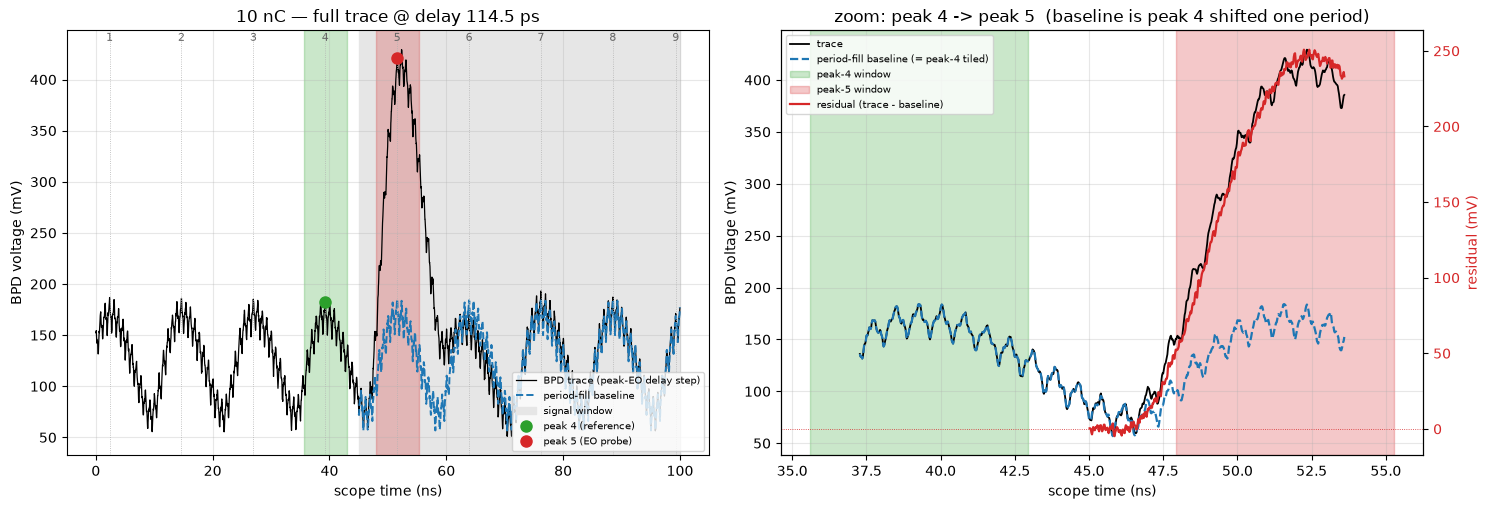

In [7]:
rec  = scans[-1]                                  # 10 nC, best SNR
step = int(np.abs(rec['pf_signed']).argmax())     # the single delay step with the strongest EO
t   = rec['t_ns']
tr  = rec['traces_raw'][step]                     # single delay step (10-shot avg) -- EO NOT washed out
bl  = rec['pf_baseline'][step]
i0  = int(round(SIGNAL_START_NS/_dt)); i1 = int(round(SIGNAL_END_NS/_dt))

fig, (axL, axR) = plt.subplots(1, 2, figsize=(15, 5.2))

# -- left: whole trace at the peak-EO delay step
axL.plot(t, MV*tr, 'k', lw=0.9, label='BPD trace (peak-EO delay step)')
axL.plot(t[i0:i1], MV*bl[i0:i1], 'C0--', lw=1.4, label='period-fill baseline')
axL.axvspan(SIGNAL_START_NS, SIGNAL_END_NS, color='0.9', zorder=0, label='signal window')
for k, i in enumerate(peak_idxs):
    axL.axvline(t[i], color='0.7', lw=0.6, ls=':')
    axL.text(t[i], MV*tr.max()*1.02, str(k+1), ha='center', fontsize=8, color='0.4')
axL.axvspan(t[pk4]-win_ns, t[pk4]+win_ns, color='tab:green', alpha=0.25)
axL.axvspan(t[pk5]-win_ns, t[pk5]+win_ns, color='tab:red',   alpha=0.25)
axL.plot(t[pk4], MV*tr[pk4], 'o', color='tab:green', ms=8, label='peak 4 (reference)')
axL.plot(t[pk5], MV*tr[pk5], 'o', color='tab:red',   ms=8, label='peak 5 (EO probe)')
axL.set_xlabel('scope time (ns)'); axL.set_ylabel('BPD voltage (mV)')
axL.set_title(f'{rec["label"]} — full trace @ delay {rec["delay_ps"][step]:.1f} ps'); axL.legend(fontsize=7, loc='lower right')
axL.grid(alpha=0.3)

# -- right: zoom peak4 -> peak5, with the actual residual on a twin axis
m = (t > t[pk4]-2) & (t < t[pk5]+2)
axR.plot(t[m], MV*tr[m], 'k', lw=1.3, label='trace')
axR.plot(t[m], MV*bl[m], 'C0--', lw=1.6, label='period-fill baseline (= peak-4 tiled)')
axR.axvspan(t[pk4]-win_ns, t[pk4]+win_ns, color='tab:green', alpha=0.25, label='peak-4 window')
axR.axvspan(t[pk5]-win_ns, t[pk5]+win_ns, color='tab:red',   alpha=0.25, label='peak-5 window')
axR.set_xlabel('scope time (ns)'); axR.set_ylabel('BPD voltage (mV)')
axR.set_title('zoom: peak 4 -> peak 5  (baseline is peak 4 shifted one period)')
axT = axR.twinx()
resid = MV*(tr - bl)
mr = m & (t >= SIGNAL_START_NS)
axT.plot(t[mr], resid[mr], color='tab:red', lw=1.6, label='residual (trace - baseline)')
axT.axhline(0, color='tab:red', lw=0.6, ls=':')
axT.set_ylabel('residual (mV)', color='tab:red'); axT.tick_params(axis='y', labelcolor='tab:red')
h1,l1 = axR.get_legend_handles_labels(); h2,l2 = axT.get_legend_handles_labels()
axR.legend(h1+h2, l1+l2, fontsize=7, loc='upper left'); axR.grid(alpha=0.3)

plt.tight_layout(); plt.savefig('Results/method_comparison/01_anatomy.png', dpi=170, bbox_inches='tight'); plt.show()

## 2 · Method A alone — peak 5 $-$ peak 4 (extrema extraction)

The 4th- and 5th-peak window maxima track together as a common-mode carrier
(left); their difference (right) is the recovered signal. The difference is almost
entirely **positive** — taking `max` of each window captures the EO signal only
when it *adds* to the carrier peak; a negative EO excursion barely lowers the
window maximum, so the negative lobe of the sweep is largely invisible to this
metric.

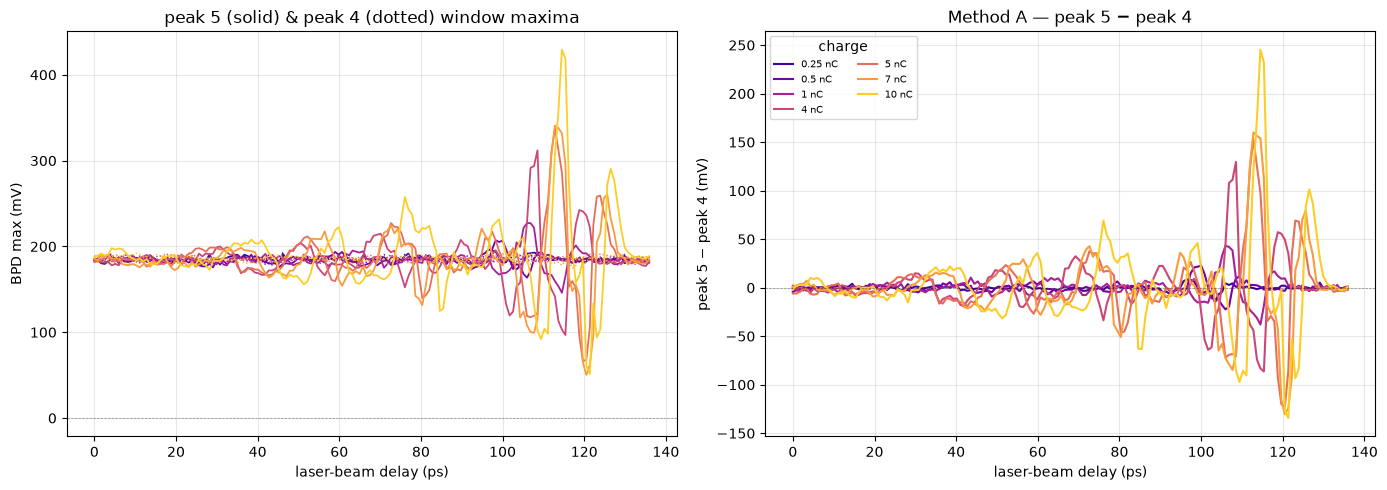

In [8]:
fig, (axA, axB) = plt.subplots(1, 2, figsize=(14, 5))
for r, col in zip(scans, colors):
    axA.plot(r['delay_ps'], MV*r['peak5_max'], color=col, lw=1.3)
    axA.plot(r['delay_ps'], MV*r['peak4_max'], color=col, lw=1.0, ls=':')
    axB.plot(r['delay_ps'], MV*r['peak_diff'], color=col, lw=1.5, label=r['label'])
axA.set_title('peak 5 (solid) & peak 4 (dotted) window maxima'); axA.set_ylabel('BPD max (mV)')
axB.set_title('Method A — peak 5 $-$ peak 4'); axB.set_ylabel('peak 5 $-$ peak 4 (mV)')
for ax in (axA, axB):
    ax.axhline(0, color='k', lw=0.5, ls='--', alpha=0.4); ax.set_xlabel('laser-beam delay (ps)'); ax.grid(alpha=0.3)
axB.legend(title='charge', fontsize=7, ncol=2)
plt.tight_layout(); plt.savefig('Results/method_comparison/02_methodA_peakdiff.png', dpi=170, bbox_inches='tight'); plt.show()

## 2b · Cross-check — Method A vs `extremas.py`

`extremas.py` finds every laser half-cycle by boxcar-smoothing (moving average,
width 201) and detecting mean-crossings, then records the **raw** local max/min in
each interval. Method A instead uses `scipy.find_peaks` on the grand-mean trace to
fix the peak centres, then takes the raw `max` in a $\pm0.3\,T$ window. If the two
identify the same 4th/5th-peak maxima, the logic is equivalent.

Below, `extremas.py` is run on every delay step (on the same 10-shot-averaged
trace Method A uses). A peak is matched only if `extremas.py` places a max
*interval* within $\pm0.45\,T$ of the expected peak time. Three things emerge:

1. **Where both report a maximum, they return the same value** — to within a few
   mV (scope quantisation and sub-window peak shift). The extraction logic is
   equivalent.
2. **`extremas.py` reports peak 5 as a *minimum*, not a maximum, when the EO field
   pushes its whole half-cycle below the trace mean.** `extremas.py` classifies
   every region as max-interval (above the smoothed global mean) or min-interval
   (below it) and records *one* extremum per region. So a strongly-suppressed peak
   5 leaves the max list — this is why the max-to-max comparison has gaps at high
   charge, and it is the negative-lobe blindness of §2/§4 seen from the detector's
   side.
3. **The minima themselves are detected correctly** (next cell): where a
   min-interval lands on peak 5, its value equals the raw peak-5 window minimum to
   the LSB. But because a sub-mean peak 5 *merges* with the troughs on either side
   into one ~1.5-period min-interval, `extremas.py`'s single recorded minimum
   often sits on an inter-peak trough rather than on peak 5 — so peak 5's
   amplitude is no longer separately recoverable from the mean-crossing output
   there. Method A's fixed `find_peaks` window is anchored at peak 5's time and
   does not have this problem.

In [9]:
# Run extremas.py logic on every frame; match peaks 4 & 5 (both max and min) by time.
TOL_NS = 0.45 * T_LASER_NS                       # < half a period -> unambiguous match
ex_summary = []
ex_scatter = {'A': [], 'ex': [], 'Q': []}
def _match(times, vals, t0):
    if not len(times): return np.nan
    k = np.argmin(np.abs(times - t0))
    return vals[k] if abs(times[k] - t0) < TOL_NS else np.nan

for rec in scans:
    t_ns = rec['t_ns']; nfr = rec['traces_raw'].shape[0]
    e_p5 = np.full(nfr, np.nan); e_p4 = np.full(nfr, np.nan)   # extremas MAX matched to peaks
    e_p5_min = np.full(nfr, np.nan)                             # extremas MIN matched to peak5
    for f in range(nfr):
        tmax, vmax, tmin, vmin = extremas_frame(rec['traces_raw'][f], t_ns)
        e_p5[f]     = _match(tmax, vmax, t_pk5)
        e_p4[f]     = _match(tmax, vmax, t_pk4)
        e_p5_min[f] = _match(tmin, vmin, t_pk5)
    rec['ex_peak5_max'] = e_p5; rec['ex_peak4_max'] = e_p4; rec['ex_peak5_min'] = e_p5_min
    cov5 = np.isfinite(e_p5); cov4 = np.isfinite(e_p4)
    d5 = np.abs(e_p5[cov5] - rec['peak5_max'][cov5]) * MV
    d4 = np.abs(e_p4[cov4] - rec['peak4_max'][cov4]) * MV
    # minima behaviour at the sub-mean (peak5-not-a-max) delays:
    below = ~cov5                                               # peak5 below trace mean
    n = rec['traces_raw'].shape[1]
    w5_incl = slice(max(0, pk5-half_win), pk5+half_win+1)       # inclusive peak-5 window
    raw_p5_min = rec['traces_raw'][:, w5_incl].min(axis=1)
    # a min-interval "lands on peak 5" only if its recorded minimum time is inside the window
    on_p5 = np.zeros(nfr, bool); dmin_max = 0.0
    for f in np.where(below)[0]:
        _, _, tmin, vmin = extremas_frame(rec['traces_raw'][f], t_ns)
        if len(tmin):
            k = np.argmin(np.abs(tmin - t_pk5))
            if abs(tmin[k] - t_pk5) <= win_ns:
                on_p5[f] = True
                dmin_max = max(dmin_max, abs(vmin[k] - raw_p5_min[f]) * MV)
    ex_summary.append((rec['label'], 100*cov5.mean(), 100*cov4.mean(),
                       d5.max() if d5.size else 0.0, d4.max() if d4.size else 0.0,
                       int(below.sum()), int(on_p5.sum()), int((below & ~on_p5).sum()), dmin_max))
    both = cov5 & cov4
    ex_scatter['A'].append(rec['peak_diff'][both] * MV)
    ex_scatter['ex'].append((e_p5[both] - e_p4[both]) * MV)
    ex_scatter['Q'].append(np.full(both.sum(), rec['Q_nom']))

print(f"{'scan':>8} {'p5 max cov':>11} {'p4 max cov':>11} {'max|Δp5|':>9} {'max|Δp4|':>9}"
      f" {'p5<mean':>8} {'min→p5':>7} {'merged':>7} {'|Δmin|':>7}")
for lbl, c5, c4, m5, m4, nb, nm, ng, dm in ex_summary:
    print(f'{lbl:>8} {c5:>10.0f}% {c4:>10.0f}% {m5:>9.3f} {m4:>9.3f} {nb:>8} {nm:>7} {ng:>7} {dm:>7.3f}')
print('\nMAX: where extremas reports a peak-5 maximum it equals Method A to '
      f'{max(s[3] for s in ex_summary):.2f} mV; peak 4 is exact (Δ=0).')
print(f'MIN: minima are detected correctly -- where a min-interval lands on peak 5 its value '
      f'equals the raw window min EXACTLY (max|Δ|={max(s[8] for s in ex_summary):.3f} mV).')
print('The gap is not inaccurate min-finding: at most sub-mean delays peak 5 is MERGED into a '
      '~1.5-period trough (the "merged" column), so its lone recorded minimum sits between peaks.')

    scan  p5 max cov  p4 max cov  max|Δp5|  max|Δp4|  p5<mean  min→p5  merged  |Δmin|
 0.25 nC        100%        100%     0.000     0.000        0       0       0   0.000
  0.5 nC        100%        100%     0.000     0.000        0       0       0   0.000
    1 nC        100%        100%     0.800     0.000        0       0       0   0.000
    4 nC         96%        100%    14.000     0.000        6       0       6   0.000
    5 nC         94%        100%    12.800     0.000        9       2       7   0.000
    7 nC         92%        100%    13.600     0.000       12       3       9   0.000
   10 nC         92%        100%     2.000     0.000       12       2      10   0.000

MAX: where extremas reports a peak-5 maximum it equals Method A to 14.00 mV; peak 4 is exact (Δ=0).
MIN: minima are detected correctly -- where a min-interval lands on peak 5 its value equals the raw window min EXACTLY (max|Δ|=0.000 mV).
The gap is not inaccurate min-finding: at most sub-mean delays peak 5 is 

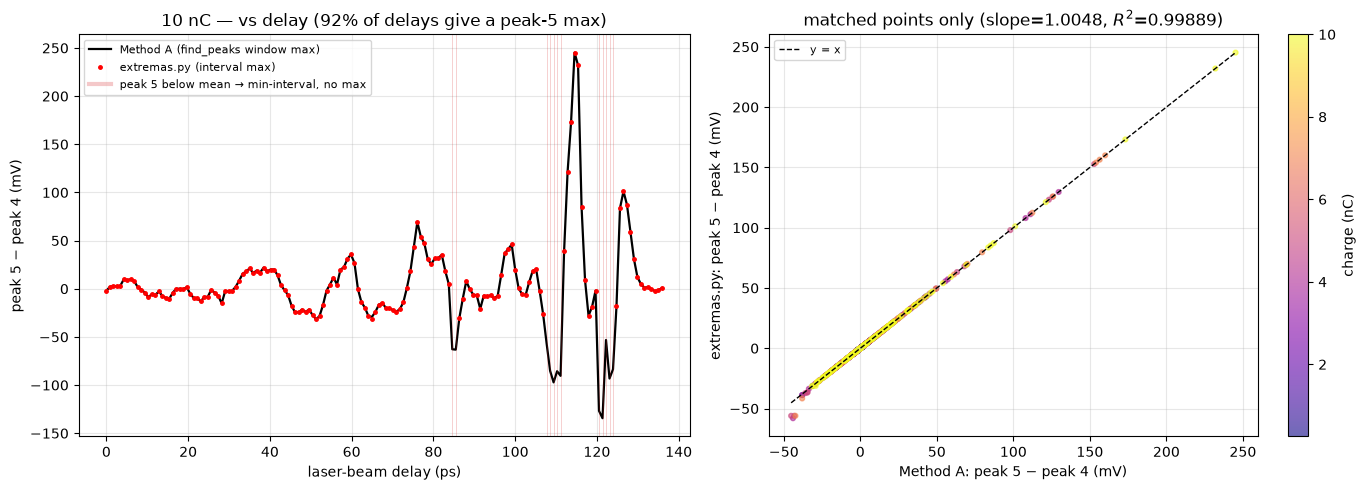

Method A vs extremas.py (matched points):  slope=1.00481  R^2=0.998893


In [10]:
# Visual confirmation: extremas.py peak5-peak4 vs Method A peak5-peak4
xA  = np.concatenate(ex_scatter['A'])
xEx = np.concatenate(ex_scatter['ex'])
Qc  = np.concatenate(ex_scatter['Q'])
lr = linregress(xA, xEx)

fig, (axA, axB) = plt.subplots(1, 2, figsize=(14, 5))
r0 = scans[-1]
det = np.isfinite(r0['ex_peak5_max'])
axA.plot(r0['delay_ps'], MV*r0['peak_diff'], 'k-', lw=1.6, label='Method A (find_peaks window max)')
axA.plot(r0['delay_ps'], MV*(r0['ex_peak5_max']-r0['ex_peak4_max']), 'r.', ms=5, label='extremas.py (interval max)')
# mark delays where peak 5 dropped below the mean -> extremas records a min, not a max
for dp in r0['delay_ps'][~det]:
    axA.axvline(dp, color='tab:red', lw=0.6, alpha=0.25)
axA.plot([], [], color='tab:red', lw=3, alpha=0.25, label='peak 5 below mean → min-interval, no max')
axA.set_xlabel('laser-beam delay (ps)'); axA.set_ylabel('peak 5 $-$ peak 4 (mV)')
axA.set_title(f'{r0["label"]} — vs delay ({100*det.mean():.0f}% of delays give a peak-5 max)')
axA.legend(fontsize=8); axA.grid(alpha=0.3)

sc = axB.scatter(xA, xEx, c=Qc, cmap='plasma', s=12, alpha=0.6)
lims = [xA.min(), xA.max()]
axB.plot(lims, lims, 'k--', lw=1, label='y = x')
axB.set_xlabel('Method A: peak 5 $-$ peak 4 (mV)'); axB.set_ylabel('extremas.py: peak 5 $-$ peak 4 (mV)')
axB.set_title(f'matched points only (slope={lr.slope:.4f}, $R^2$={lr.rvalue**2:.5f})')
axB.legend(fontsize=8); axB.grid(alpha=0.3); fig.colorbar(sc, ax=axB, label='charge (nC)')
plt.tight_layout(); plt.savefig('Results/method_comparison/02b_extremas_crosscheck.png', dpi=170, bbox_inches='tight'); plt.show()
print(f'Method A vs extremas.py (matched points):  slope={lr.slope:.5f}  R^2={lr.rvalue**2:.6f}')

## 2c · Visualizing the interval merging

`extremas.py` splits each trace into **max-intervals** (smoothed trace above its
global mean, shaded red) and **min-intervals** (below the mean, shaded blue), and
records one extremum per interval (dots). The two panels below show the same 10 nC
trace at two delays:

- **Left — peak 5 above the mean.** Peak 5 occupies its own max-interval, so it
  gets a recorded maximum (red dot on peak 5) that equals Method A's window max.
- **Right — peak 5 EO-suppressed below the mean.** Peaks 4→6 no longer rise above
  the mean between them, so their three half-cycles **fuse into a single
  ~1.5-period min-interval** (wide blue band). `extremas.py` records just one
  minimum for that whole band (blue dot), and it lands in an *inter-peak trough*,
  not on peak 5 — which is why peak 5 has neither a max nor an on-peak min in the
  output at these delays. The minimum value itself is still exact; it is simply
  located elsewhere.

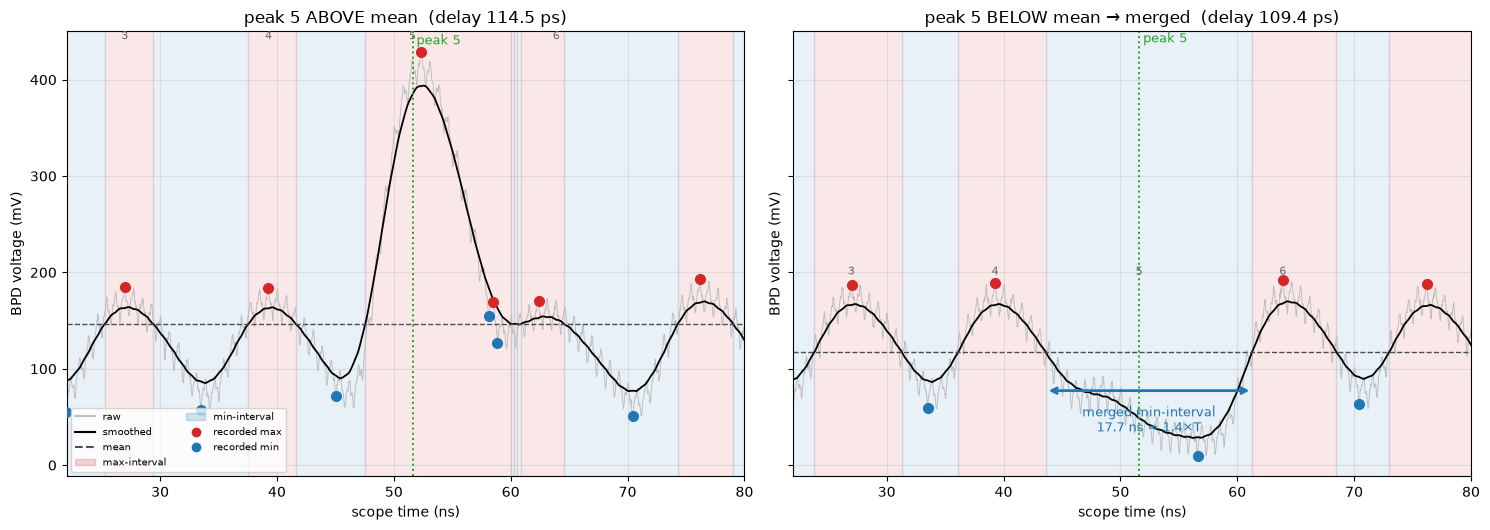

normal frame 134: peak5 above mean, own max-interval.
merged frame 128: peak5 below mean; min-interval containing peak5 spans 17.7 ns = 1.43 laser periods.


In [11]:
def extremas_intervals(BPD_raw, x_ns, window=201):
    '''Same logic as extremas_frame but also returns the interval spans for plotting.'''
    sm = moving_average(BPD_raw, window); avg = sm.mean()
    x_sm = x_ns[window // 2:-(window // 2)]
    above = sm[0] > avg; max_iv, min_iv = [], []; cs = -1
    for i, val in enumerate(sm):
        if val > avg:
            if not above:
                if cs == -1: cs = i
                else: min_iv.append((cs, i)); cs = i
        else:
            if above:
                if cs == -1: cs = i
                else: max_iv.append((cs, i)); cs = i; above = sm[i] > avg
        above = sm[i] > avg
    return sm, avg, x_sm, max_iv, min_iv

rec = scans[-1]                                     # 10 nC
det = np.isfinite(rec['ex_peak5_max'])
f_norm = int(rec['peak5_max'].argmax())             # peak 5 strongly enhanced (above mean)
below_idx = np.where(~det)[0]
# prefer a "merged-away" frame: peak 5 below mean AND its recorded min sits off peak 5,
# so the figure matches the narrative (single min lands between peaks, not on peak 5).
merged_away = []
for f in below_idx:
    _, _, _tmin, _ = extremas_frame(rec['traces_raw'][f], rec['t_ns'])
    if len(_tmin) and abs(_tmin[np.argmin(np.abs(_tmin - t_pk5))] - t_pk5) > win_ns:
        merged_away.append(f)
pool = merged_away if merged_away else list(below_idx)
f_merg = int(pool[rec['peak_diff'][pool].argmin()])   # strongest suppression among merged-away

def draw(ax, f, title):
    tr = rec['traces_raw'][f]; t = rec['t_ns']
    sm, avg, x_sm, max_iv, min_iv = extremas_intervals(tr, t)
    ax.plot(t, MV*tr, color='0.75', lw=0.7, label='raw trace')
    ax.plot(x_sm, MV*sm, 'k', lw=1.3, label='smoothed (mov-avg 201)')
    ax.axhline(MV*avg, color='0.3', ls='--', lw=1, label='trace mean')
    for s, e in max_iv:
        ax.axvspan(x_sm[s], x_sm[min(e, len(x_sm)-1)], color='tab:red',  alpha=0.10)
        j = np.argmax(tr[s:e]) + s; ax.plot(t[j], MV*tr[j], 'o', color='tab:red', ms=7, zorder=5)
    for s, e in min_iv:
        ax.axvspan(x_sm[s], x_sm[min(e, len(x_sm)-1)], color='tab:blue', alpha=0.10)
        j = np.argmin(tr[s:e]) + s; ax.plot(t[j], MV*tr[j], 'o', color='tab:blue', ms=7, zorder=5)
    ax.axvline(t_pk5, color='tab:green', lw=1.4, ls=':')
    ax.text(t_pk5, ax.get_ylim()[1], ' peak 5', color='tab:green', fontsize=9, va='top')
    for k in (3, 4, 5, 6):
        ax.text(rec['t_ns'][peak_idxs[k-1]], MV*tr.max()*1.03, str(k), ha='center', fontsize=8, color='0.4')
    ax.set_xlim(22, 80); ax.set_xlabel('scope time (ns)'); ax.set_ylabel('BPD voltage (mV)')
    ax.set_title(title); ax.grid(alpha=0.3)
    return sm, avg, x_sm, min_iv

fig, (axL, axR) = plt.subplots(1, 2, figsize=(15, 5.4), sharey=True)
draw(axL, f_norm, f'peak 5 ABOVE mean  (delay {rec["delay_ps"][f_norm]:.1f} ps)')
sm, avg, x_sm, min_iv = draw(axR, f_merg, f'peak 5 BELOW mean → merged  (delay {rec["delay_ps"][f_merg]:.1f} ps)')

# annotate the merged min-interval width on the right panel
containing = [(s, e) for s, e in min_iv if x_sm[s]-1 <= t_pk5 <= x_sm[min(e, len(x_sm)-1)]+1]
if containing:
    s, e = containing[0]; t0, t1 = x_sm[s], x_sm[min(e, len(x_sm)-1)]; ymrk = MV*avg - 40
    axR.annotate('', xy=(t0, ymrk), xytext=(t1, ymrk),
                 arrowprops=dict(arrowstyle='<->', color='tab:blue', lw=2))
    axR.text((t0+t1)/2, ymrk-14, f'merged min-interval\n{t1-t0:.1f} ns ≈ {(t1-t0)/T_LASER_NS:.1f}×T',
             color='tab:blue', ha='center', va='top', fontsize=9)

from matplotlib.patches import Patch
from matplotlib.lines import Line2D
handles = [Line2D([0],[0],color='0.75',lw=1.5,label='raw'), Line2D([0],[0],color='k',lw=1.5,label='smoothed'),
           Line2D([0],[0],color='0.3',ls='--',label='mean'),
           Patch(color='tab:red',alpha=0.2,label='max-interval'), Patch(color='tab:blue',alpha=0.2,label='min-interval'),
           Line2D([0],[0],marker='o',color='tab:red',ls='',label='recorded max'),
           Line2D([0],[0],marker='o',color='tab:blue',ls='',label='recorded min')]
axL.legend(handles=handles, fontsize=7, loc='lower left', ncol=2)
plt.tight_layout(); plt.savefig('Results/method_comparison/02c_interval_merging.png', dpi=170, bbox_inches='tight'); plt.show()
print(f'normal frame {f_norm}: peak5 above mean, own max-interval.')
print(f'merged frame {f_merg}: peak5 below mean; min-interval containing peak5 spans '
      f'{(t1-t0):.1f} ns = {(t1-t0)/T_LASER_NS:.2f} laser periods.')

## 2d · The same two delays under period fill — how it avoids the problem

Same trace, same two delays, same zoom as §2c — but now showing **Method B**. Period
fill never asks whether peak 5 is above or below a global mean. It (1) lays down a
baseline equal to the clean pre-window (peak-4) period tiled forward — the blue
dashed curve — and (2) reads the signed residual (trace $-$ baseline, purple fill)
in a **fixed probe window** anchored at peak 5's time (green band). Because the
window is anchored in time, not defined by mean-crossings, peak 5 is recovered at
**both** delays:

- **Left (enhanced):** the trace rides far above the tiled baseline → large
  **positive** signed amplitude.
- **Right (suppressed):** the trace dips below the tiled baseline → **negative**
  signed amplitude — the very delay where `extremas.py` merged peak 5 into a trough
  and lost it (§2c). Period fill reports it cleanly, with the correct sign.

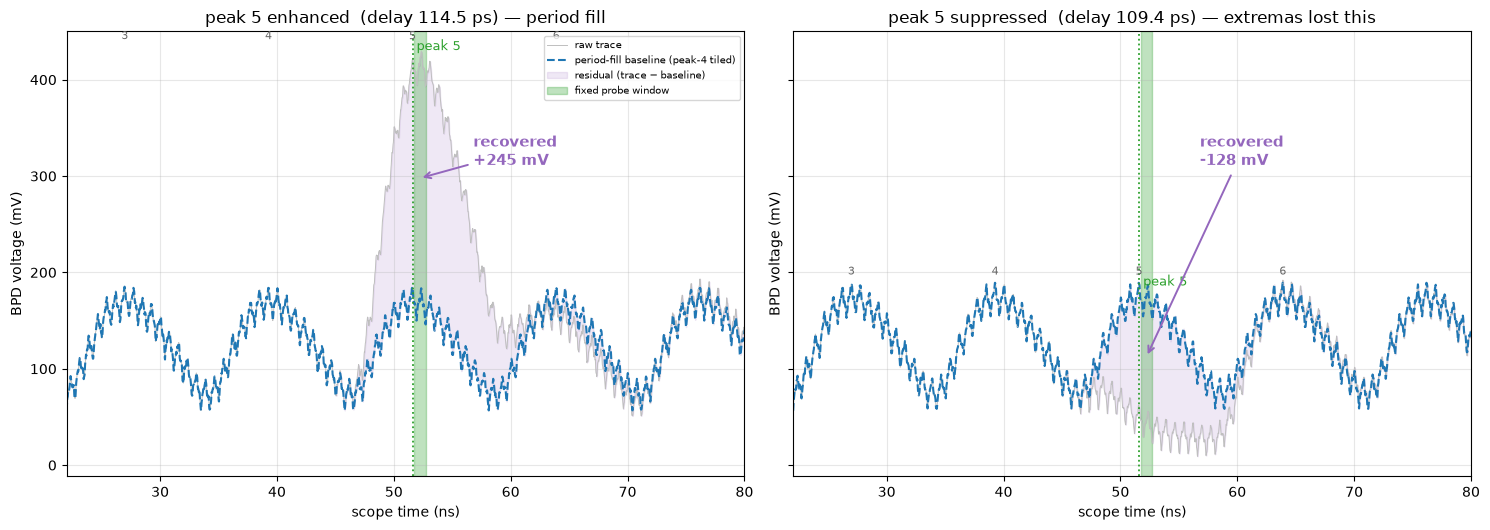

period fill recovers:  enhanced frame 134: +245.5 mV   suppressed frame 128: -128.3 mV
(extremas.py peak5 max at suppressed frame: NOT detected — merged into a trough)


In [12]:
rec = scans[-1]; t = rec['t_ns']
tp = rec['pf_tp']; win = rec['pf_win']
tw0, tw1 = t[win.start], t[win.stop - 1]

def draw_pf(ax, f, tag):
    tr = rec['traces_raw'][f]; bl = rec['pf_baseline'][f]
    sig = t >= SIGNAL_START_NS
    ax.plot(t, MV*tr, color='0.75', lw=0.7, label='raw trace')
    ax.plot(t, MV*bl, 'C0--', lw=1.5, label='period-fill baseline (peak-4 tiled)')
    ax.fill_between(t, MV*bl, MV*tr, where=sig, color='tab:purple', alpha=0.15,
                    label='residual (trace − baseline)')
    ax.axvspan(tw0, tw1, color='tab:green', alpha=0.30, label='fixed probe window')
    ax.axvline(t_pk5, color='tab:green', lw=1.3, ls=':')
    ax.text(t_pk5, ax.get_ylim()[1] if False else MV*tr.max()*1.03, ' peak 5',
            color='tab:green', fontsize=9, va='top')
    for k in (3, 4, 5, 6):
        ax.text(rec['t_ns'][peak_idxs[k-1]], MV*tr.max()*1.03, str(k), ha='center', fontsize=8, color='0.4')
    val = MV * rec['pf_signed'][f]
    mid = MV * 0.5 * (tr[tp] + bl[tp])                 # visible point inside the probe window
    ax.annotate(f'recovered\n{val:+.0f} mV', xy=(0.5*(tw0+tw1), mid), xycoords='data',
                xytext=(0.60, 0.70), textcoords='axes fraction', color='tab:purple',
                fontsize=11, fontweight='bold', ha='left',
                arrowprops=dict(arrowstyle='->', color='tab:purple', lw=1.4))
    ax.set_xlim(22, 80); ax.set_xlabel('scope time (ns)'); ax.set_ylabel('BPD voltage (mV)')
    ax.set_title(tag); ax.grid(alpha=0.3)

fig, (axL, axR) = plt.subplots(1, 2, figsize=(15, 5.4), sharey=True)
draw_pf(axL, f_norm, f'peak 5 enhanced  (delay {rec["delay_ps"][f_norm]:.1f} ps) — period fill')
draw_pf(axR, f_merg, f'peak 5 suppressed  (delay {rec["delay_ps"][f_merg]:.1f} ps) — extremas lost this')
axL.legend(fontsize=7, loc='upper right')
plt.tight_layout(); plt.savefig('Results/method_comparison/02d_periodfill_same_area.png', dpi=170, bbox_inches='tight'); plt.show()
print(f'period fill recovers:  enhanced frame {f_norm}: {MV*rec["pf_signed"][f_norm]:+.1f} mV   '
      f'suppressed frame {f_merg}: {MV*rec["pf_signed"][f_merg]:+.1f} mV')
print(f'(extremas.py peak5 max at suppressed frame: '
      f'{"detected" if np.isfinite(rec["ex_peak5_max"][f_merg]) else "NOT detected — merged into a trough"})')

## 2e · Fixing period fill's blind spot — extremum on the residual

Period fill's readout is the mean of a **fixed** $\pm25$-sample ($\pm0.5$ ns) window
at one probe time. But the EO feature **shifts in time** with delay (its extremum
wanders ~7 ns across a scan — over half a laser period, and it sits *outside* the
fixed window ~45 % of the time). A fixed window can't follow it, so it can
under-capture a shifted excursion.

The fix combines the strengths of both methods: **period-fill background removal**
(subtract the tiled peak-4 carrier — works whether peak 5 is above or below the
mean, §2d) followed by the **`extremas` idea applied to the residual** — instead of
fixing the averaging window at one time, *slide* it and take the signed value at
the position of **largest fluctuation**, so it moves with the peak.

**Important — do it the `extremas` way (smooth, then extract), not raw.** A raw
single-sample `argmax|residual|` rectifies noise: at delays where the true signal
is ~0 it still returns the largest noise spike (a ~10 mV floor vs the fixed
window's ~4 mV). So we slide the *same ±25-sample averaging window* (equivalent to
smoothing first, exactly what `extremas.py` does with its moving average) and take
its extremum. That keeps the noise floor near the fixed window's while following
the peak. The gain here is modest (~10–15 % on the negative lobe, since this
residual feature is broad); it would matter more for a sharper, faster-moving
peak.

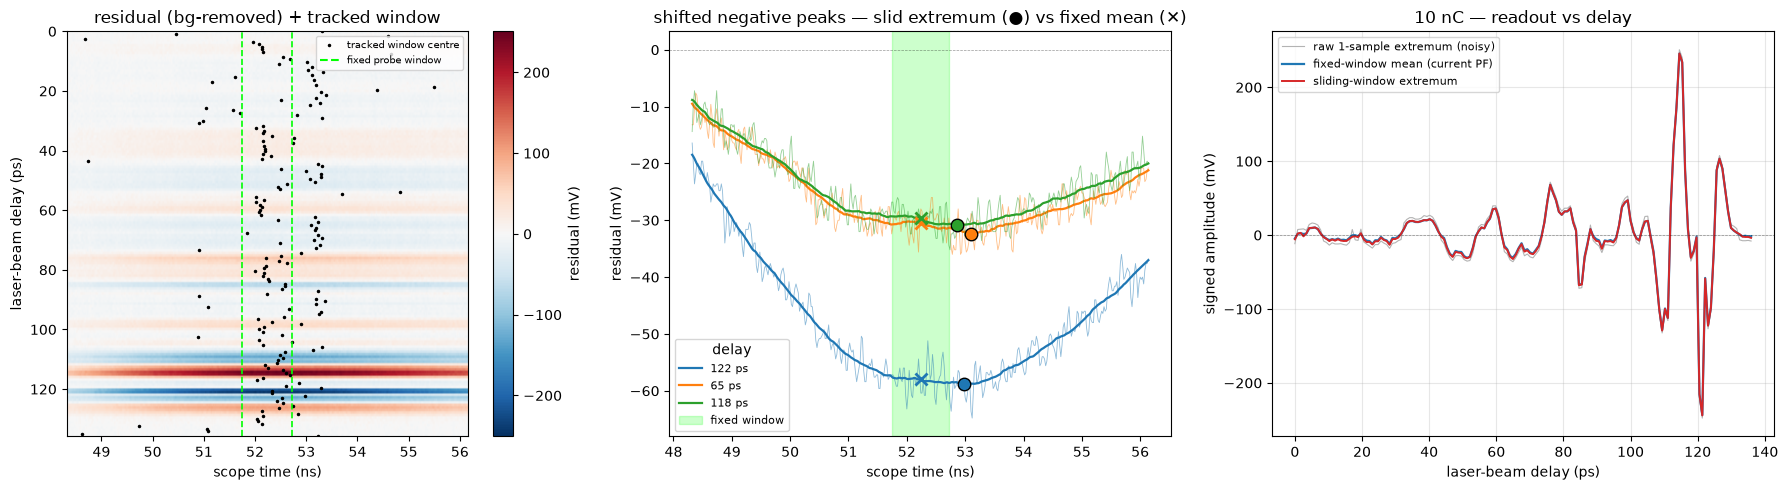

peak wanders 48.62–55.50 ns; outside fixed window 45% of delays.
noise floor (weak-signal delays, should be ~0): fixed 4.2 mV | sliding-ext 5.2 mV | raw-ext 10.0 mV (rectifies noise).
negative-lobe median magnitude: fixed -9.9 mV -> sliding-ext -11.1 mV (1.13×).


In [13]:
from scipy.ndimage import uniform_filter1d
rec = scans[-1]                                    # 10 nC
t = rec['t_ns']; res = rec['pf_res']; tp = rec['pf_tp']
sh = int(0.3 * T_LASER_NS / _dt)                   # search half-window = +/-0.3 T
sw = slice(tp - sh, tp + sh)
twf = (t[rec['pf_win'].start], t[rec['pf_win'].stop - 1])   # the fixed +/-25-sample window
Wwin = 2 * PROBE_HALF_WIN + 1                       # same width as the current probe window

# slide the SAME averaging window, take its extremum (noise-robust "largest fluctuation")
slid = uniform_filter1d(res, Wwin, axis=1, mode='nearest')
seg  = slid[:, sw]; j = np.argmax(np.abs(seg), axis=1)
ext  = np.take_along_axis(seg, j[:, None], axis=1)[:, 0]    # sliding-window extremum (V)
text = t[sw][j]                                            # its location (tracks the shift)
fixed = rec['pf_signed']                                    # current fixed-window mean (V)
# raw single-sample extremum -- shown only to expose its noise rectification
segr = res[:, sw]; jr = np.argmax(np.abs(segr), axis=1)
ext_raw = np.take_along_axis(segr, jr[:, None], axis=1)[:, 0]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
wlo, whi = tp - sh - 12, tp + sh + 12

# Panel 1 — residual heat + tracked (sliding) window centre
extent = [t[wlo], t[whi], rec['delay_ps'][-1], rec['delay_ps'][0]]
vmx = MV*np.abs(res[:, wlo:whi]).max()
im = axes[0].imshow(MV*res[:, wlo:whi], aspect='auto', extent=extent, cmap='RdBu_r', vmin=-vmx, vmax=vmx)
axes[0].plot(text, rec['delay_ps'], 'k.', ms=3, label='tracked window centre')
axes[0].axvline(twf[0], color='lime', lw=1.2, ls='--'); axes[0].axvline(twf[1], color='lime', lw=1.2, ls='--')
axes[0].plot([], [], color='lime', ls='--', label='fixed probe window')
axes[0].set_xlabel('scope time (ns)'); axes[0].set_ylabel('laser-beam delay (ps)')
axes[0].set_title('residual (bg-removed) + tracked window'); axes[0].legend(fontsize=7, loc='upper right')
fig.colorbar(im, ax=axes[0], label='residual (mV)')

# Panel 2 — example residual traces where the peak shifted out of the fixed window
sm_show = slid                                     # smoothed residual for the markers
cand = np.where((ext < 0) & (np.abs(text - t[tp]) > PROBE_HALF_WIN*_dt))[0]
sel = cand[np.argsort(ext[cand])[:3]] if cand.size >= 3 else cand
for s, c in zip(sel, ['tab:blue', 'tab:orange', 'tab:green']):
    axes[1].plot(t[wlo:whi], MV*res[s, wlo:whi], color=c, lw=0.6, alpha=0.5)
    axes[1].plot(t[wlo:whi], MV*sm_show[s, wlo:whi], color=c, lw=1.6, label=f'{rec["delay_ps"][s]:.0f} ps')
    axes[1].plot(text[s], MV*ext[s],   'o', color=c, ms=9, mec='k', zorder=5)   # slid extremum
    axes[1].plot(t[tp],  MV*fixed[s], 'x', color=c, ms=9, mew=2, zorder=5)      # fixed readout
axes[1].axvspan(twf[0], twf[1], color='lime', alpha=0.20, label='fixed window')
axes[1].axhline(0, color='k', lw=0.5, ls='--', alpha=0.4)
axes[1].set_xlabel('scope time (ns)'); axes[1].set_ylabel('residual (mV)')
axes[1].set_title('shifted negative peaks — slid extremum (●) vs fixed mean (✕)')
axes[1].legend(fontsize=8, title='delay')

# Panel 3 — readout vs delay: fixed vs sliding extremum (+ raw extremum to show noise)
axes[2].plot(rec['delay_ps'], MV*ext_raw, color='0.7', lw=0.8, label='raw 1-sample extremum (noisy)')
axes[2].plot(rec['delay_ps'], MV*fixed, color='tab:blue', lw=1.6, label='fixed-window mean (current PF)')
axes[2].plot(rec['delay_ps'], MV*ext,  color='tab:red',  lw=1.4, label='sliding-window extremum')
axes[2].axhline(0, color='k', lw=0.5, ls='--', alpha=0.4)
axes[2].set_xlabel('laser-beam delay (ps)'); axes[2].set_ylabel('signed amplitude (mV)')
axes[2].set_title(f'{rec["label"]} — readout vs delay'); axes[2].legend(fontsize=8); axes[2].grid(alpha=0.3)
plt.tight_layout(); plt.savefig('Results/method_comparison/02e_residual_extremum.png', dpi=170, bbox_inches='tight'); plt.show()

neg = fixed < 0
weak = np.abs(fixed) < np.quantile(np.abs(fixed), 0.4)
print(f'peak wanders {text.min():.2f}–{text.max():.2f} ns; outside fixed window '
      f'{100*(np.abs(text-t[tp])>PROBE_HALF_WIN*_dt).mean():.0f}% of delays.')
print(f'noise floor (weak-signal delays, should be ~0): fixed {MV*np.median(np.abs(fixed[weak])):.1f} mV | '
      f'sliding-ext {MV*np.median(np.abs(ext[weak])):.1f} mV | raw-ext '
      f'{MV*np.median(np.abs(ext_raw[weak])):.1f} mV (rectifies noise).')
print(f'negative-lobe median magnitude: fixed {MV*np.median(fixed[neg]):.1f} mV -> '
      f'sliding-ext {MV*np.median(ext[neg]):.1f} mV ({np.median(ext[neg])/np.median(fixed[neg]):.2f}×).')

## 2f · Per-trace walkthrough — raw → baseline → residual → extrema

A few illustrative delay steps, one per row. **Left:** the raw 10-shot-averaged
trace with the period-fill baseline (the tiled peak-4 carrier) laid over it.
**Right:** the residual (raw $-$ baseline) with the extrema found on it — maxima
(red ▲), minima (blue ▼), and the single **largest fluctuation** (black ring),
which is the signed EO amplitude for that delay. The green band marks period fill's
*fixed* probe window; note how the largest fluctuation can sit outside it (§2e).

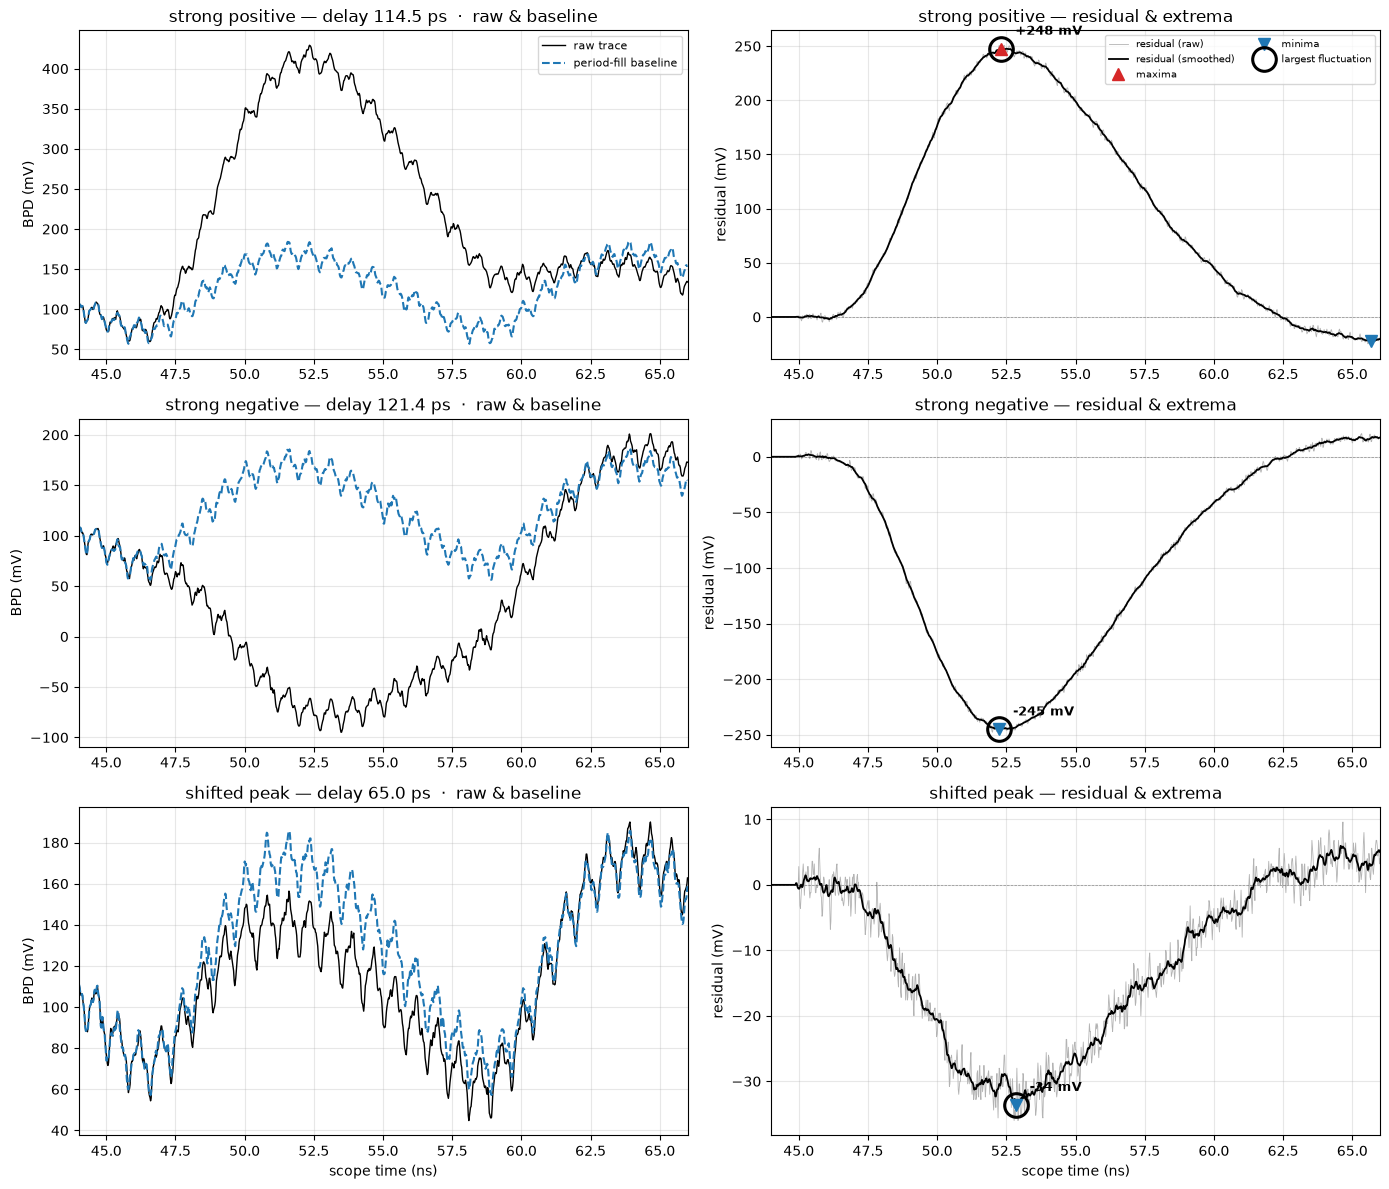

illustrative delays: [('strong positive', np.float64(114.5)), ('strong negative', np.float64(121.4)), ('shifted peak', np.float64(65.0))]


In [ ]:
from scipy.ndimage import uniform_filter1d
rec = scans[-1]; t = rec['t_ns']; fixed = rec['pf_signed']; tp = rec['pf_tp']
twf = (t[rec['pf_win'].start], t[rec['pf_win'].stop - 1])
ZOOM = (44, 66)                                              # scope-time window to display
z = (t >= ZOOM[0]) & (t <= ZOOM[1])

def resid_extrema(r):
    sm = uniform_filter1d(r, 11, mode='nearest')            # ~0.2 ns light smoothing
    dist = int(0.4 * T_LASER_NS / _dt); prom = 5e-3         # >=5 mV, >=0.4 T apart
    mx, _ = find_peaks(sm,  distance=dist, prominence=prom)
    mn, _ = find_peaks(-sm, distance=dist, prominence=prom)
    keep = lambda idx: idx[(t[idx] >= SIGNAL_START_NS) & (t[idx] <= ZOOM[1])]
    return sm, keep(mx), keep(mn)

# choose illustrative delays: strongest +, strongest -, and a shifted-peak case
sh = int(0.3*T_LASER_NS/_dt); sw = slice(tp-sh, tp+sh)
slid = uniform_filter1d(rec['pf_res'], 2*PROBE_HALF_WIN+1, axis=1, mode='nearest')
tshift = np.abs(t[sw][np.argmax(np.abs(slid[:, sw]), axis=1)] - t[tp])
cand = np.where((np.abs(fixed) > 0.03) & (tshift > PROBE_HALF_WIN*_dt))[0]
f_shift = int(cand[np.argmax(tshift[cand])]) if cand.size else int(tshift.argmax())
rows = [('strong positive', int(fixed.argmax())),
        ('strong negative', int(fixed.argmin())),
        ('shifted peak',     f_shift)]

fig, axes = plt.subplots(len(rows), 2, figsize=(14, 4.0*len(rows)))
for ri, (tag, f) in enumerate(rows):
    tr_f = rec['traces_raw'][f]; bl_f = rec['pf_baseline'][f]; r_f = rec['pf_res'][f]
    sm, mx, mn = resid_extrema(r_f)
    axL, axR = axes[ri]

    axL.plot(t[z], MV*tr_f[z], 'k', lw=1.0, label='raw trace')
    axL.plot(t[z], MV*bl_f[z], 'C0--', lw=1.5, label='period-fill baseline')
    axL.set_xlim(*ZOOM); axL.set_ylabel('Balanced Photodiode Output (mV)'); axL.grid(alpha=0.3)
    axL.set_title(f'{tag} — delay {rec["delay_ps"][f]:.1f} ps  ·  raw & baseline')

    axR.plot(t[z], MV*r_f[z], color='0.7', lw=0.6, label='residual (raw)')
    axR.plot(t[z], MV*sm[z], 'k', lw=1.3, label='residual (smoothed)')
    axR.axhline(0, color='k', lw=0.5, ls='--', alpha=0.4)
    if len(mx): axR.plot(t[mx], MV*sm[mx], '^', color='tab:red',  ms=8, ls='', label='maxima')
    if len(mn): axR.plot(t[mn], MV*sm[mn], 'v', color='tab:blue', ms=8, ls='', label='minima')
    allx = np.concatenate([mx, mn]) if (len(mx)+len(mn)) else np.array([tp])
    jbig = allx[np.argmax(np.abs(sm[allx]))]
    axR.plot(t[jbig], MV*sm[jbig], 'o', mfc='none', mec='k', ms=17, mew=2.2,
             label='largest fluctuation', zorder=6)
    axR.annotate(f'{MV*sm[jbig]:+.0f} mV', (t[jbig], MV*sm[jbig]),
                 textcoords='offset points', xytext=(10, 10), fontweight='bold', fontsize=9)
    axR.set_xlim(*ZOOM); axR.set_ylabel('residual (mV)'); axR.grid(alpha=0.3)
    axR.set_title(f'{tag} — residual & extrema')
    if ri == 0:
        axL.legend(fontsize=8, loc='upper right'); axR.legend(fontsize=7, loc='upper right', ncol=2)
axes[-1, 0].set_xlabel('scope time (ns)'); axes[-1, 1].set_xlabel('scope time (ns)')
plt.tight_layout(); plt.savefig('Results/method_comparison/02f_per_trace_walkthrough.png', dpi=170, bbox_inches='tight'); plt.show()
print('illustrative delays:', [(tag, round(rec['delay_ps'][f],1)) for tag, f in rows])

## 3 · Method B alone — period fill (unfiltered)

Left: the residual (trace $-$ baseline, **no filter**) versus delay and scope time
for one charge — the EO signature is the bipolar streak at the probe time. Right:
the resulting **signed amplitude vs delay** for every charge. Because the readout
keeps its sign, the characteristic positive-then-negative EO sweep is preserved.
Without the low-pass the residual is visibly grainier than in the filtered version.

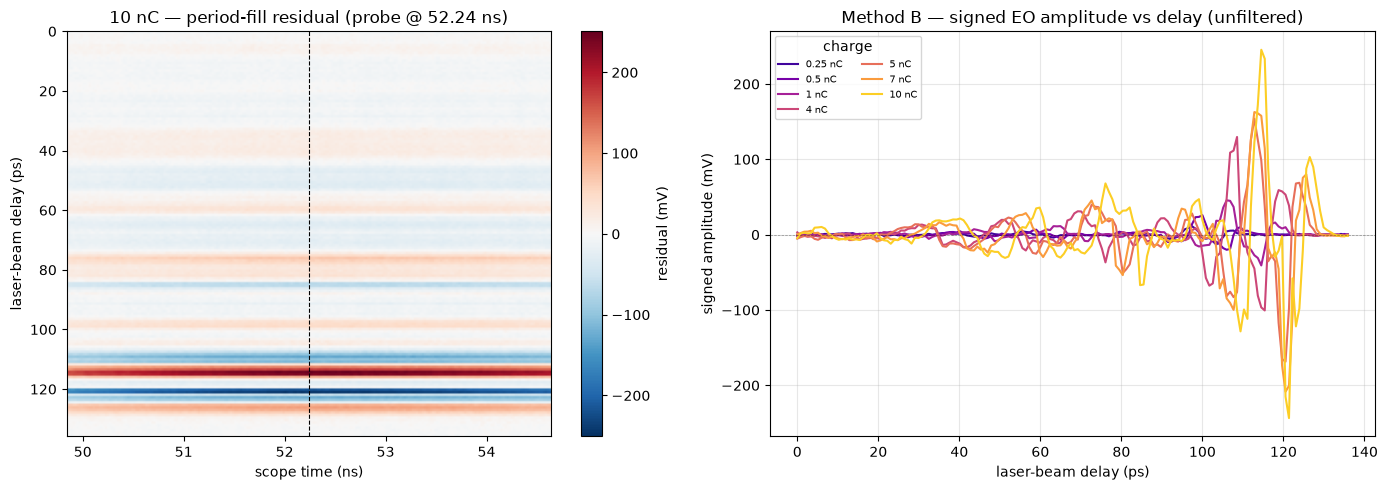

In [15]:
rec = scans[-1]
fig, (axA, axB) = plt.subplots(1, 2, figsize=(14, 5))
tp = rec['pf_tp']; wlo, whi = tp-120, tp+120
ext = [rec['t_ns'][wlo], rec['t_ns'][whi], rec['delay_ps'][-1], rec['delay_ps'][0]]
vmx = MV*np.abs(rec['pf_res'][:,wlo:whi]).max()
im = axA.imshow(MV*rec['pf_res'][:, wlo:whi], aspect='auto', extent=ext, cmap='RdBu_r', vmin=-vmx, vmax=vmx)
axA.axvline(rec['t_ns'][tp], color='k', lw=0.8, ls='--')
axA.set_xlabel('scope time (ns)'); axA.set_ylabel('laser-beam delay (ps)')
axA.set_title(f'{rec["label"]} — period-fill residual (probe @ {rec["t_ns"][tp]:.2f} ns)')
fig.colorbar(im, ax=axA, label='residual (mV)')

for r, col in zip(scans, colors):
    axB.plot(r['delay_ps'], MV*r['pf_signed'], color=col, lw=1.5, label=r['label'])
axB.axhline(0, color='k', lw=0.5, ls='--', alpha=0.4)
axB.set_xlabel('laser-beam delay (ps)'); axB.set_ylabel('signed amplitude (mV)')
axB.set_title('Method B — signed EO amplitude vs delay (unfiltered)'); axB.grid(alpha=0.3)
axB.legend(title='charge', fontsize=7, ncol=2)
plt.tight_layout(); plt.savefig('Results/method_comparison/03_methodB_periodfill.png', dpi=170, bbox_inches='tight'); plt.show()

## 4 · Head to head — both signals vs delay

Overlaying the two curves (period-fill signed amplitude vs peak 5 $-$ peak 4). On
the **positive** lobe the two agree closely — confirming they measure the same EO
response. They diverge where the EO signal swings **negative**: period fill
follows it below zero, the naive two-peak `max` difference flattens near zero. The
right panel is the residual between methods.

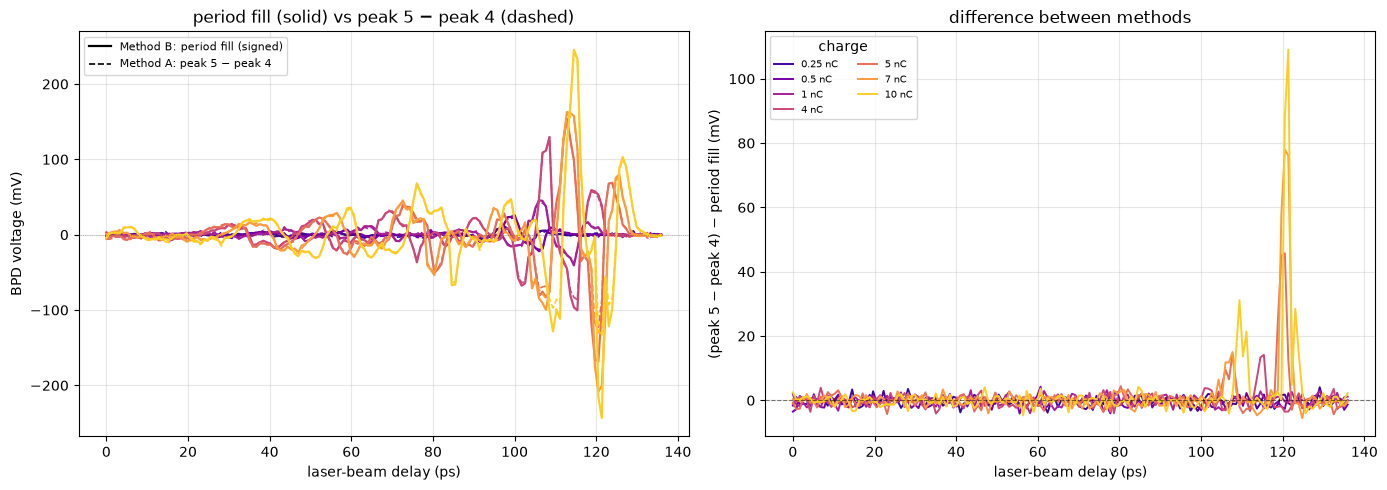

In [16]:
fig, (axA, axB) = plt.subplots(1, 2, figsize=(14, 5))
from matplotlib.lines import Line2D
for r, col in zip(scans, colors):
    axA.plot(r['delay_ps'], MV*r['pf_signed'], color=col, lw=1.6, ls='-')
    axA.plot(r['delay_ps'], MV*r['peak_diff'], color=col, lw=1.2, ls='--')
    axB.plot(r['delay_ps'], MV*(r['peak_diff'] - r['pf_signed']), color=col, lw=1.4, label=r['label'])
axA.axhline(0, color='k', lw=0.5, ls=':', alpha=0.4)
axA.set_xlabel('laser-beam delay (ps)'); axA.set_ylabel('BPD voltage (mV)')
axA.set_title('period fill (solid) vs peak 5 $-$ peak 4 (dashed)')
hs = [Line2D([0],[0],color='k',lw=1.6,ls='-',label='Method B: period fill (signed)'),
      Line2D([0],[0],color='k',lw=1.2,ls='--',label='Method A: peak 5 $-$ peak 4')]
axA.legend(handles=hs, fontsize=8); axA.grid(alpha=0.3)
axB.axhline(0, color='k', lw=0.8, ls='--', alpha=0.5)
axB.set_xlabel('laser-beam delay (ps)'); axB.set_ylabel('(peak 5 $-$ peak 4) $-$ period fill (mV)')
axB.set_title('difference between methods'); axB.grid(alpha=0.3); axB.legend(title='charge', fontsize=7, ncol=2)
plt.tight_layout(); plt.savefig('Results/method_comparison/04_overlay.png', dpi=170, bbox_inches='tight'); plt.show()

## 5 · Correlation — every (delay, charge) point

Each point is one delay step of one scan: $x=$ Method A (peak 5 $-$ peak 4),
$y=$ Method B (period-fill signed amplitude). A tight line through the origin with
slope ≈ 1 means the methods are interchangeable. The asymmetry noted above appears
as the fan-out where period fill goes negative but peak-diff stays near zero.

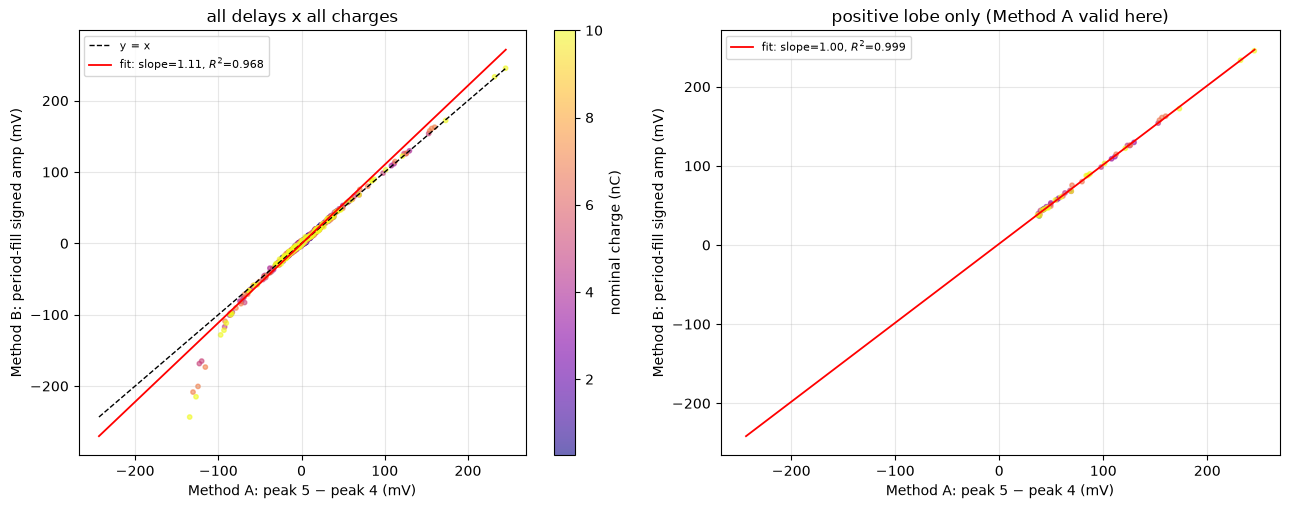

ALL points : slope=1.108  R^2=0.968
POS lobe   : slope=0.999  R^2=0.999


In [17]:
x = np.concatenate([r['peak_diff'] for r in scans]) * MV
y = np.concatenate([r['pf_signed'] for r in scans]) * MV
cvec = np.concatenate([[r['Q_nom']]*r['delay_ps'].size for r in scans])
lr = linregress(x, y)

fig, (axA, axB) = plt.subplots(1, 2, figsize=(13, 5.2))
sc = axA.scatter(x, y, c=cvec, cmap='plasma', s=10, alpha=0.6)
lims = [min(x.min(), y.min()), max(x.max(), y.max())]
axA.plot(lims, lims, 'k--', lw=1, label='y = x')
axA.plot(lims, lr.intercept + lr.slope*np.array(lims), 'r-', lw=1.3,
         label=f'fit: slope={lr.slope:.2f}, $R^2$={lr.rvalue**2:.3f}')
axA.set_xlabel('Method A: peak 5 $-$ peak 4 (mV)'); axA.set_ylabel('Method B: period-fill signed amp (mV)')
axA.set_title('all delays x all charges'); axA.legend(fontsize=8); axA.grid(alpha=0.3)
fig.colorbar(sc, ax=axA, label='nominal charge (nC)')

pos = x > 0.15*x.max()
lrp = linregress(x[pos], y[pos])
axB.scatter(x[pos], y[pos], c=cvec[pos], cmap='plasma', s=10, alpha=0.6)
axB.plot(lims, lrp.intercept + lrp.slope*np.array(lims), 'r-', lw=1.3,
         label=f'fit: slope={lrp.slope:.2f}, $R^2$={lrp.rvalue**2:.3f}')
axB.set_xlabel('Method A: peak 5 $-$ peak 4 (mV)'); axB.set_ylabel('Method B: period-fill signed amp (mV)')
axB.set_title('positive lobe only (Method A valid here)'); axB.legend(fontsize=8); axB.grid(alpha=0.3)
plt.tight_layout(); plt.savefig('Results/method_comparison/05_correlation.png', dpi=170, bbox_inches='tight'); plt.show()
print(f'ALL points : slope={lr.slope:.3f}  R^2={lr.rvalue**2:.3f}')
print(f'POS lobe   : slope={lrp.slope:.3f}  R^2={lrp.rvalue**2:.3f}')

## 6 · Charge scaling — does the physics survive either reduction?

The headline deliverable is EO response vs bunch charge. Here the peak EO metric
per scan (max over delay) is plotted against nominal charge for both methods. If
both are linear with the same slope, either method supports the same physics
conclusion — the choice is then about noise and sign, not bias.

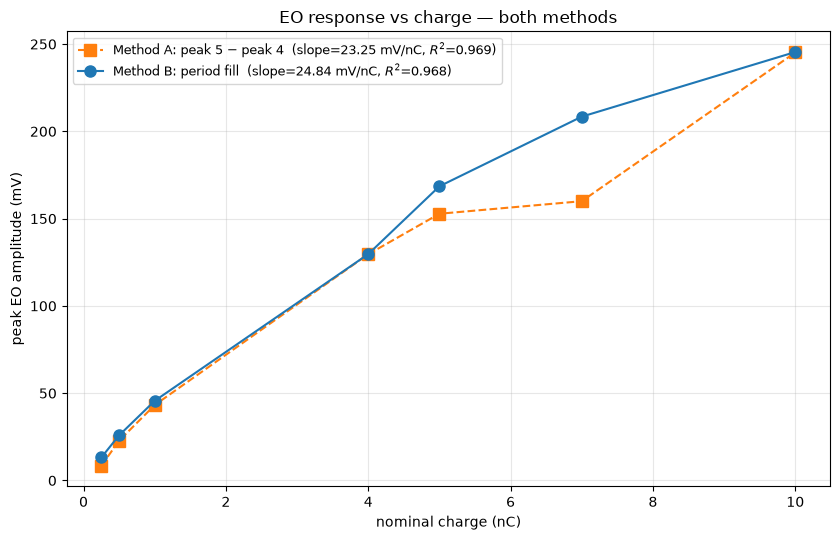

In [18]:
Q   = np.array([r['Q_nom'] for r in scans])
A_pf = np.array([np.abs(r['pf_signed']).max() for r in scans]) * MV
A_pk = np.array([r['peak_diff'].max()        for r in scans]) * MV
lpf, lpk = linregress(Q, A_pf), linregress(Q, A_pk)

fig, ax = plt.subplots(figsize=(8.5, 5.5))
ax.plot(Q, A_pk, 's--', color='tab:orange', ms=8, label=f'Method A: peak 5 $-$ peak 4  (slope={lpk.slope:.2f} mV/nC, $R^2$={lpk.rvalue**2:.3f})')
ax.plot(Q, A_pf, 'o-', color='tab:blue',   ms=8, label=f'Method B: period fill  (slope={lpf.slope:.2f} mV/nC, $R^2$={lpf.rvalue**2:.3f})')
ax.set_xlabel('nominal charge (nC)'); ax.set_ylabel('peak EO amplitude (mV)')
ax.set_title('EO response vs charge — both methods'); ax.grid(alpha=0.3); ax.legend(fontsize=9)
plt.tight_layout(); plt.savefig('Results/method_comparison/06_charge_scaling.png', dpi=170, bbox_inches='tight'); plt.show()

## 7 · Noise floor & SNR

With the FFT low-pass removed, period fill's only remaining noise advantage is
averaging over its $\pm25$-sample probe window (~50 samples) versus Method A's two
single-sample maxima. We estimate each method's noise as the standard deviation of
its signal over the **off-EO delay steps** (the flat baseline region far from the
EO sweep), and define SNR = peak signal / that noise.

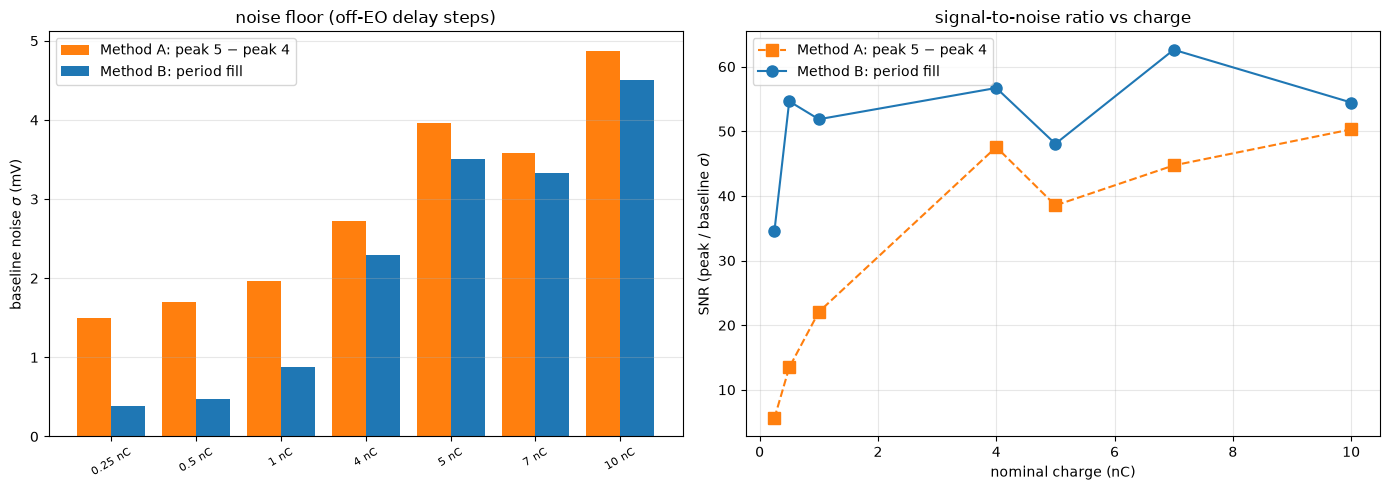

median noise:  period-fill 2.287 mV   peak-diff 2.725 mV   ->  1.2x lower with period fill
median SNR:    period-fill 54.5      peak-diff 38.5


In [19]:
def off_eo_mask(sig):
    '''Delay steps whose |signal| is in the lowest 40% -> baseline (EO-free) region.'''
    a = np.abs(sig - np.median(sig))
    return a < np.quantile(a, 0.40)

rows = []
for r in scans:
    m = off_eo_mask(r['pf_signed'])
    n_pf = r['pf_signed'][m].std(ddof=1) * MV
    n_pk = r['peak_diff'][m].std(ddof=1) * MV
    s_pf = np.abs(r['pf_signed']).max() * MV
    s_pk = r['peak_diff'].max() * MV
    rows.append((r['label'], r['Q_nom'], n_pf, n_pk, s_pf/n_pf, s_pk/n_pk))

lbls = [x[0] for x in rows]; Qs = np.array([x[1] for x in rows])
npf = np.array([x[2] for x in rows]); npk = np.array([x[3] for x in rows])
spf = np.array([x[4] for x in rows]); spk = np.array([x[5] for x in rows])

fig, (axA, axB) = plt.subplots(1, 2, figsize=(14, 5))
xb = np.arange(len(lbls))
axA.bar(xb-0.2, npk, 0.4, color='tab:orange', label='Method A: peak 5 $-$ peak 4')
axA.bar(xb+0.2, npf, 0.4, color='tab:blue',   label='Method B: period fill')
axA.set_xticks(xb); axA.set_xticklabels(lbls, rotation=30, fontsize=8)
axA.set_ylabel('baseline noise $\\sigma$ (mV)'); axA.set_title('noise floor (off-EO delay steps)')
axA.legend(); axA.grid(alpha=0.3, axis='y')

axB.plot(Qs, spk, 's--', color='tab:orange', ms=8, label='Method A: peak 5 $-$ peak 4')
axB.plot(Qs, spf, 'o-', color='tab:blue',   ms=8, label='Method B: period fill')
axB.set_xlabel('nominal charge (nC)'); axB.set_ylabel('SNR (peak / baseline $\\sigma$)')
axB.set_title('signal-to-noise ratio vs charge'); axB.grid(alpha=0.3); axB.legend()
plt.tight_layout(); plt.savefig('Results/method_comparison/07_noise_snr.png', dpi=170, bbox_inches='tight'); plt.show()

print(f'median noise:  period-fill {np.median(npf):.3f} mV   peak-diff {np.median(npk):.3f} mV'
      f'   ->  {np.median(npk)/np.median(npf):.1f}x lower with period fill')
print(f'median SNR:    period-fill {np.median(spf):.1f}      peak-diff {np.median(spk):.1f}')

## 8 · Trace-by-trace (per-shot) agreement

Both reductions can be applied to each of the 10 individual shots per delay step
instead of the shot average. Pooling every shot at every delay across all charges
gives the per-trace correlation cloud — the shot-level analog of §5. The spread
around the fit line is the single-shot disagreement between methods.

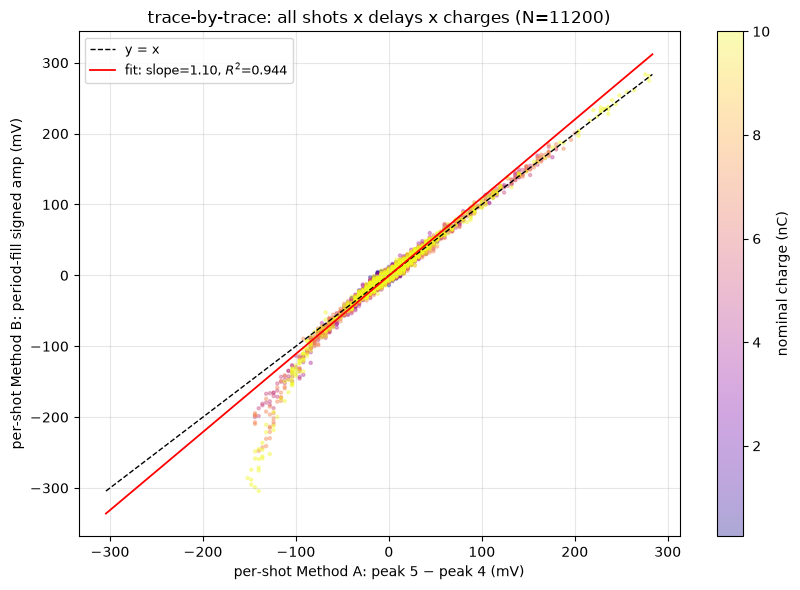

per-shot correlation: slope=1.102  R^2=0.944  N=11200


In [20]:
xs = np.concatenate([r['peak_diff_ps'].ravel() for r in scans]) * MV
ys = np.concatenate([r['pf_signed_ps'].ravel() for r in scans]) * MV
cs = np.concatenate([np.full(r['peak_diff_ps'].size, r['Q_nom']) for r in scans])
lrs = linregress(xs, ys)

fig, ax = plt.subplots(figsize=(8.5, 6))
sc = ax.scatter(xs, ys, c=cs, cmap='plasma', s=5, alpha=0.35)
lims = [min(xs.min(), ys.min()), max(xs.max(), ys.max())]
ax.plot(lims, lims, 'k--', lw=1, label='y = x')
ax.plot(lims, lrs.intercept + lrs.slope*np.array(lims), 'r-', lw=1.3,
        label=f'fit: slope={lrs.slope:.2f}, $R^2$={lrs.rvalue**2:.3f}')
ax.set_xlabel('per-shot Method A: peak 5 $-$ peak 4 (mV)')
ax.set_ylabel('per-shot Method B: period-fill signed amp (mV)')
ax.set_title(f'trace-by-trace: all shots x delays x charges (N={xs.size})')
ax.legend(fontsize=9); ax.grid(alpha=0.3)
fig.colorbar(sc, ax=ax, label='nominal charge (nC)')
plt.tight_layout(); plt.savefig('Results/method_comparison/08_per_shot.png', dpi=170, bbox_inches='tight'); plt.show()
print(f'per-shot correlation: slope={lrs.slope:.3f}  R^2={lrs.rvalue**2:.3f}  N={xs.size}')

## 9 · Merits — summary

**Method A matches `extremas.py`'s extraction** (§2b): both return the same
4th/5th-peak maxima to within a few mV (scope quantisation), and the same minima to
the LSB where a min-interval lands on the peak — so Method A *is* the `extremas.py`
logic, just windowed by `find_peaks` instead of by mean-crossing intervals. One
structural caveat surfaced: `extremas.py` records only *one* extremum per
above/below-mean interval, so when the EO field pushes peak 5 below the trace mean
(~8% of high-charge delays) peak 5 leaves the max list and merges into a
~1.5-period min-interval whose lone minimum sits between peaks — peak 5 is no
longer separately recoverable from the mean-crossing output there. Method A's
fixed, time-anchored window does not have this problem.

**The two baseline methods agree where both are valid.** On the positive EO lobe
they are linearly related with slope ≈ 1 and high $R^2$ (§5), and both give the
same linear EO-vs-charge scaling (§6). So the two-peak subtraction is *not wrong* —
it is the coarse limit of period fill and reproduces the headline physics.

**Where they differ (both now unfiltered):**

| | Method A — peak 5 $-$ peak 4 (`extremas.py`) | Method B — period fill (unfiltered) |
|---|---|---|
| **Sign / bipolarity** | `max`-based → blind to negative EO excursions (§2, §4) | keeps sign — captures the full positive→negative sweep |
| **Noise** | two single-sample maxima → noisiest | averages ~50 samples in the probe window → modestly lower $\sigma$ (§7) |
| **Baseline fidelity** | assumes peak-4 height ≡ peak-5 unmodulated height | models the carrier shape *and slope* across the window |
| **Probe selection** | fixed by peak finder / mean-crossing | automatic (max-variance sample) |
| **Transparency** | dead simple, every number traceable to a physical peak; matches legacy `extremas.py` | more machinery (probe window, period alignment) |
| **Robustness** | robust to slow drift via adjacent-peak common-mode rejection | needs stationary, well-aligned periodicity |

**Recommendation.**
- **Method B (period fill)** for the reported EO amplitude, charge scaling, and
  anything where the negative lobe or SNR matters — it is the more faithful and
  (even without the filter) quieter estimator.
- **Method A (peak 5 $-$ peak 4 / `extremas.py`)** as the transparent,
  parameter-free cross-check. Its agreement with period fill on the positive lobe
  (§5–§6) validates that the period-fill machinery isn't manufacturing signal; its
  disagreement on the negative lobe concretely shows what the extra machinery buys.

All figures are written to `Results/method_comparison/`.